1# 영업 메일 에이전트 — 윈스테크넷 "스나이퍼 APT"

여러 에이전트를 **어떤 방식으로 엮을 것인가**를 배우는 노트북입니다.
**OpenAI Agents SDK**를 사용합니다.
같은 시나리오를 다른 프레임워크로 만든 노트북이 함께 있습니다 — `langchain_agent_code.ipynb`, `langgraph_agent_code.ipynb`.

## 시나리오

여러분은 **주식회사 윈스테크넷**의 **스나이퍼 APT** 제품을 파는 Sales Group 소속입니다.
팀에는 메일 쓰는 스타일이 전혀 다른 판매원 세 명이 있습니다.

| | 성향 | 어떻게 쓰나 |
|---|---|---|
| 판매원1 | **매우 정직** | 과장하지 않고 사실만. 못 하는 것도 밝힘 |
| 판매원2 | **유머러스** | 가볍고 재미있게. 읽는 부담을 줄임 |
| 판매원3 | **매우 공격적** | "안 사면 회사가 망할 수 있다"는 식으로 압박 |

세 명에게 각각 초안을 쓰게 하고, 그중 가장 좋은 하나를 골라 보내는 것이 목표입니다.

## 이 노트북에서 배우는 것

에이전트를 엮는 방법은 크게 세 가지입니다. 순서대로 만들어 보고 비교합니다.

| 방식 | 누가 흐름을 정하나 | 이 노트북의 단계 |
|---|---|---|
| **코드로 엮기** | 우리가 파이썬으로 | Step 3 ~ 7 |
| **에이전트를 도구로** | LLM이 도구를 골라서 | Step 8 |
| **핸드오프** | LLM이 다른 에이전트에게 넘겨서 | Step 9 |

> **실행 순서**: 위에서부터 차례대로 실행하세요. 앞 셀에서 만든 변수를 뒤에서 씁니다.
> 이 노트북은 `agent/` 폴더에서 실행하는 것을 전제로 합니다.

## Step 0. 준비

필요한 것을 불러오고 모델을 정합니다.

`agents`는 OpenAI Agents SDK입니다. 이름이 비슷한 세 가지를 먼저 구분해 두세요.

| 이름 | 무엇인가 |
|---|---|
| `Agent` | 에이전트 하나. **지시문(instructions)이 곧 성격**입니다 |
| `Runner` | 에이전트를 실제로 돌리는 실행기 |
| `trace` | 여러 호출을 하나의 작업으로 묶어 기록. 나중에 웹에서 흐름을 볼 수 있습니다 |

In [3]:
import asyncio
import os
import smtplib
from email.message import EmailMessage

from dotenv import load_dotenv
from agents import Agent, Runner, trace, function_tool, ModelSettings
from openai.types.responses import ResponseTextDeltaEvent

load_dotenv(override=True)

MODEL_NAME = "gpt-5.4-mini"
print("모델:", MODEL_NAME)

모델: gpt-5.4-mini


## Step 1. 메일 보내기 준비 (안전장치 포함)

에이전트가 마지막에 메일을 "보내는" 단계까지 만들 것이므로, 발송 함수를 먼저 준비합니다.

### 먼저 안전장치부터

이 노트북에는 **실습 중 실수로 메일이 나가지 않도록** 스위치를 하나 두었습니다.

```python
SEND_FOR_REAL = False   # 기본값: 보내지 않고 화면에만 보여준다
```

`False`인 동안에는 발송 대신 내용을 화면에 출력합니다. 학습에는 이걸로 충분합니다.

**왜 이렇게 하나?** 에이전트는 우리가 예상하지 못한 순간에 도구를 부릅니다.
뒤에서 `tool_choice="required"`로 **반드시 도구를 쓰게** 만드는 단계도 나오는데,
그때 셀을 몇 번 다시 실행하면 그만큼 메일이 나갑니다.
메일은 한 번 나가면 되돌릴 수 없습니다. 되돌릴 수 없는 동작은 기본을 꺼 두는 편이 낫습니다.

실제로 보내 보고 싶다면 아래 셀에서 `SEND_FOR_REAL = True`로 바꾸세요.
`.env`에 `EMAIL_ADDRESS`, `EMAIL_SMTP_SERVER`, `EMAIL_APP_PASSWORD`가 필요합니다.

In [17]:
EMAIL_ADDRESS = os.getenv("EMAIL_ADDRESS")
EMAIL_SMTP_SERVER = os.getenv("EMAIL_SMTP_SERVER")
EMAIL_APP_PASSWORD = os.getenv("EMAIL_APP_PASSWORD")

# 실제 발송 스위치. True로 바꾸면 진짜 메일이 나갑니다.
SEND_FOR_REAL = True

HAS_EMAIL_CONFIG = all([EMAIL_ADDRESS, EMAIL_SMTP_SERVER, EMAIL_APP_PASSWORD])

print("메일 설정:", "있음" if HAS_EMAIL_CONFIG else "없음")
print("발송 모드:", "실제 발송" if SEND_FOR_REAL else "미리보기 (화면 출력만)")

메일 설정: 있음
발송 모드: 실제 발송


### 발송 함수 두 개

역할을 나눠 둡니다. 섞어 놓으면 나중에 바꾸기 어렵습니다.

| 함수 | 하는 일 |
|---|---|
| `send_email` | SMTP로 **실제** 발송. 이 함수는 조건을 따지지 않습니다 |
| `send_message` | 스위치를 보고 **발송할지 출력할지 결정**. 에이전트는 이쪽만 씁니다 |

In [18]:
def send_email(subject, text_body):
    """SMTP로 실제 메일을 보낸다. 자기 자신에게 보낸다."""
    msg = EmailMessage()
    msg["From"] = EMAIL_ADDRESS
    msg["To"] = EMAIL_ADDRESS
    msg["Subject"] = subject
    msg.set_content(text_body)

    with smtplib.SMTP(EMAIL_SMTP_SERVER, 587) as server:
        server.starttls()
        server.login(EMAIL_ADDRESS, EMAIL_APP_PASSWORD)
        server.send_message(msg)


def send_message(subject, text_body):
    """스위치를 보고 실제로 보낼지 화면에 보여줄지 정한다."""
    if SEND_FOR_REAL and HAS_EMAIL_CONFIG:
        send_email(subject, text_body)
        return "메일을 실제로 보냈습니다."

    print("=" * 66)
    print("[미리보기] 실제로 보내지 않았습니다")
    print("제목:", subject)
    print("-" * 66)
    print(text_body)
    print("=" * 66)
    return "미리보기로 출력했습니다."

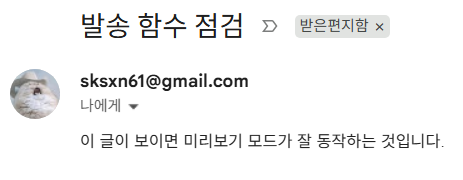

In [19]:
send_message("발송 함수 점검", "이 글이 보이면 미리보기 모드가 잘 동작하는 것입니다.")

'메일을 실제로 보냈습니다.'

## Step 2. 판매원 세 명 만들기

에이전트를 만드는 데 필요한 것은 사실상 **지시문 하나**입니다.

```python
Agent(name="이름", instructions="어떻게 행동할지", model="어떤 모델")
```

세 판매원은 **같은 회사, 같은 제품, 같은 모델**을 씁니다.
다른 것은 지시문의 성향 부분 한 줄뿐입니다.
이렇게 해야 나중에 결과를 비교할 때 **무엇 때문에 달라졌는지** 분명해집니다.
바꾸는 변수를 하나로 두는 것이 실험의 기본입니다.

### 공통 배경을 따로 빼는 이유

`intro`를 변수로 빼고 세 지시문에 더했습니다. 제품 설명이 바뀌면 한 곳만 고치면 됩니다.
세 군데에 복사해 두면 한 곳을 빠뜨렸을 때 **그 판매원만 옛 정보로 메일을 씁니다.**
그런 오류는 결과만 봐서는 알아차리기 어렵습니다.

In [7]:
intro = """당신은 주식회사 윈스테크넷의 영업 담당자입니다.
'스나이퍼 APT'라는 지능형 지속 위협(APT) 대응 솔루션을 판매합니다.
이 제품은 알려지지 않은 악성코드와 표적 공격을 네트워크 단에서 탐지하고 차단합니다.
당신의 일은 잠재 고객에게 보낼 영업 메일을 쓰는 것입니다.
메일은 한국어로 쓰고, 제목과 본문을 모두 포함하세요.
"""

instructions1 = intro + """당신의 메일 스타일은 매우 정직합니다.
과장하거나 부풀리지 않습니다. 확인된 사실만 씁니다.
제품이 해결하지 못하는 부분이 있다면 그것도 솔직하게 밝힙니다."""

instructions2 = intro + """당신의 메일 스타일은 유머러스합니다.
가볍고 재치 있는 표현으로 읽는 사람의 부담을 덜어줍니다.
다만 제품 정보 자체는 정확하게 전달합니다."""

instructions3 = intro + """당신의 메일 스타일은 매우 공격적입니다.
이 제품을 도입하지 않으면 고객사가 큰 피해를 입고 사업이 무너질 수 있다는 점을 강하게 압박합니다.
위기감을 최대한 강조하고 즉시 결정할 것을 요구합니다."""

In [8]:
sales_agent1 = Agent(name="정직한 판매원", instructions=instructions1, model=MODEL_NAME)
sales_agent2 = Agent(name="유머러스한 판매원", instructions=instructions2, model=MODEL_NAME)
sales_agent3 = Agent(name="공격적인 판매원", instructions=instructions3, model=MODEL_NAME)

for agent in [sales_agent1, sales_agent2, sales_agent3]:
    print(f"{agent.name:16} 모델={agent.model}")

정직한 판매원          모델=gpt-5.4-mini
유머러스한 판매원        모델=gpt-5.4-mini
공격적인 판매원         모델=gpt-5.4-mini


## Step 3. 한 명 실행해 보기 — 스트리밍

먼저 판매원1만 돌려 봅니다. 여기서는 **스트리밍**으로 받습니다.

| 방식 | 언제 결과가 오나 |
|---|---|
| `Runner.run` | 답변이 **다 끝난 뒤** 한 번에 |
| `Runner.run_streamed` | 글자가 만들어지는 **대로 조금씩** |

메일 한 통은 수백 토큰이라 다 기다리면 십여 초가 걸립니다.
사용자 화면이 그동안 멈춰 있으면 고장난 것처럼 보입니다.
스트리밍은 결과를 빨리 만들어 주지는 않지만, **기다리는 느낌**을 크게 줄여 줍니다.

아래 코드의 `if`가 하는 일: 스트림에는 여러 종류의 사건이 섞여 옵니다
(도구 호출, 에이전트 전환 등). 그중 **글자 조각(`ResponseTextDeltaEvent`)만** 골라 출력합니다.

In [9]:
result = Runner.run_streamed(sales_agent1, input="영업 메일 초안을 하나 써 주세요")

async for event in result.stream_events():
    if event.type == "raw_response_event" and isinstance(event.data, ResponseTextDeltaEvent):
        print(event.data.delta, end="", flush=True)

제목: 스나이퍼 APT 소개 및 검토 요청드립니다

안녕하세요,  
윈스테크넷 영업 담당자입니다.

당사 APT 대응 솔루션 **스나이퍼 APT**를 소개드리고자 연락드립니다.  
스나이퍼 APT는 **네트워크 단에서 알려지지 않은 악성코드와 표적 공격을 탐지하고 차단**하는 제품입니다.

다만 솔직히 말씀드리면, 스나이퍼 APT가 **모든 공격을 완전히 막아주는 것은 아닙니다.**  
특히 단말 자체의 상태, 계정 탈취, 내부 사용자 행위 등은 네트워크 장비만으로는 확인에 한계가 있을 수 있습니다.  
그래서 보통은 기존 보안 체계와 함께 운영하는 방식이 적합합니다.

관심 있으시면  
- 제품 개요  
- 적용 방식  
- 도입 시 확인할 사항  

을 간단히 정리해 드리겠습니다.

검토 가능하신 일정이 있으시면 편하게 회신 부탁드립니다.  
감사합니다.

윈스테크넷  
영업 담당자 드림

## Step 4. 세 명을 동시에 실행 — 병렬

세 판매원은 서로를 기다릴 이유가 없습니다. 각자 독립적으로 메일을 씁니다.
그러면 **동시에** 돌리는 편이 낫습니다.

```python
await asyncio.gather(A, B, C)     # 셋을 함께 시작하고 다 끝나면 돌려준다
```

하나에 10초씩 걸린다면 차례로 돌릴 때는 30초, 동시에 돌리면 10초입니다.
LLM 호출은 대부분의 시간을 **응답을 기다리는 데** 쓰기 때문에 이런 이득이 큽니다.

### `with trace(...)`는 무엇인가

세 번의 호출을 **하나의 작업으로 묶어** 기록합니다.
묶지 않으면 로그에 호출 세 개가 따로 찍혀서, 나중에 보면 어느 것이 한 세트였는지 알 수 없습니다.
기록은 <https://platform.openai.com/traces> 에서 볼 수 있습니다.

In [33]:
message = "영업 메일 초안을 하나 써 주세요"

with trace("판매원 3인 병렬 초안"):
    results = await asyncio.gather(
        Runner.run(sales_agent1, message),
        Runner.run(sales_agent2, message),
        Runner.run(sales_agent3, message),
    )

drafts = [r.final_output for r in results]
names = ["판매원1 (정직)", "판매원2 (유머)", "판매원3 (공격)"]

for name, draft in zip(names, drafts):
    print("=" * 66)
    print(name)
    print("=" * 66)
    print(draft)
    print()

판매원1 (정직)
**제목:** 네트워크 단에서 알려지지 않은 위협 대응이 필요하신 경우, 스나이퍼 APT를 소개드립니다

안녕하세요.  
윈스테크넷 영업 담당자입니다.

저희 **스나이퍼 APT**는 **네트워크 단에서 알려지지 않은 악성코드와 표적 공격을 탐지하고 차단하는 APT 대응 솔루션**입니다.

다음과 같은 상황에서 검토해 보실 수 있습니다.  
- 기존 보안 장비만으로는 대응이 어려운 위협을 추가로 확인하고 싶을 때  
- 알려지지 않은 악성코드나 표적 공격에 대한 탐지 범위를 넓히고 싶을 때  
- 네트워크 구간에서 의심스러운 행위를 식별하고 차단하고 싶을 때

다만 솔직히 말씀드리면, **스나이퍼 APT만으로 모든 위협을 막을 수는 없습니다.**  
단말기 내부에서 발생하는 문제, 계정 탈취, 사용자의 직접적인 실수 등은 별도의 보안 체계와 함께 보시는 것이 필요합니다.

관심 있으시면 간단히 제품 자료를 보내드리거나, 현재 환경에 맞는 적용 가능 범위를 함께 확인해 드리겠습니다.  
편하신 방식으로 회신 주시면 감사하겠습니다.

감사합니다.  
윈스테크넷 드림

판매원2 (유머)
물론입니다. 아래처럼 가볍고 재치 있게 써볼 수 있습니다.

**제목:**  
보이지 않는 위협, 네트워크에서 먼저 잡아보시겠습니까? – 스나이퍼 APT 소개드립니다

**본문:**  
안녕하세요, 담당자님.  
주식회사 윈스테크넷의 영업 담당자입니다.

요즘 공격자들은 참 부지런합니다.  
우리가 커피 마시는 사이에도 몰래 들어오려 하니, 보안도 이제 “눈치게임”이 아니라 “선제 대응”이 필요하더라고요.

그래서 소개드리고 싶은 솔루션이 **스나이퍼 APT**입니다.  
스나이퍼 APT는 **알려지지 않은 악성코드와 표적 공격(APT)**을 **네트워크 단에서 탐지하고 차단**하는 지능형 위협 대응 솔루션입니다.

즉, 이상한 움직임이 보이면  
“잠깐, 거기 누구세요?” 하고 먼저 확인한 뒤,  
필요하면 아주 단호하게 막아줍니다.  
(보안은 친절하되, 침입자

### 세 초안이 얼마나 다른가

눈으로도 보이지만, 간단한 숫자로도 확인해 봅니다.
성향이 결과에 정말 반영됐는지 **지시문만 보고 믿지 말고 결과로 확인하는 습관**을 들이세요.

In [34]:
print(f"{'':16} {'글자수':>6} {'느낌표':>6} {'물음표':>6}")
for name, draft in zip(names, drafts):
    print(f"{name:16} {len(draft):>6} {draft.count('!'):>6} {draft.count('?'):>6}")

# 위기감을 자극하는 낱말이 얼마나 쓰였는지도 세어 본다.
FEAR_WORDS = ["위험", "피해", "위협", "치명", "심각", "즉시", "지금", "손실", "마비", "붕괴"]
print()
for name, draft in zip(names, drafts):
    hits = {w: draft.count(w) for w in FEAR_WORDS if w in draft}
    total = sum(hits.values())
    print(f"{name:16} 위기 낱말 {total:>3}회  {hits}")

                    글자수    느낌표    물음표
판매원1 (정직)           545      0      0
판매원2 (유머)           723      0      2
판매원3 (공격)           669      0      0

판매원1 (정직)        위기 낱말   3회  {'위협': 3}
판매원2 (유머)        위기 낱말   3회  {'위협': 3}
판매원3 (공격)        위기 낱말  10회  {'위험': 1, '피해': 2, '위협': 2, '즉시': 1, '지금': 3, '마비': 1}


## Step 5. 고르는 에이전트

초안 세 개 중 하나를 골라야 합니다. 이 판단도 에이전트에게 맡깁니다.

여기서 지시문의 한 줄이 중요합니다.

> **고객 입장이 되어** 답장하고 싶은 메일을 고르세요.

이 말이 없으면 모델은 "잘 쓴 글"을 고릅니다. 우리가 원하는 것은 **답장이 오는 글**입니다.
둘은 다릅니다. **평가 기준을 적어 주지 않으면 모델이 자기 기준으로 고릅니다.**

In [35]:
decision = """당신은 여러 영업 메일 초안 중 가장 좋은 것 하나를 고릅니다.
당신이 이 메일을 받는 고객이라고 상상하고, 답장하고 싶은 메일을 고르세요.
설명은 하지 말고 선택한 메일 전문만 그대로 출력하세요.
"""

sales_picker = Agent(name="메일 선택자", instructions=decision, model=MODEL_NAME)
print("선택 에이전트 준비 완료")

선택 에이전트 준비 완료


In [36]:
# 초안들을 하나의 글로 합쳐서 넘긴다.
emails = "영업 메일 초안들:\n\n" + "\n\n---다음 초안---\n\n".join(drafts)

with trace("메일 선택"):
    best = await Runner.run(sales_picker, emails)

print("선택된 메일:\n")
print(best.final_output)

선택된 메일:

안녕하세요.  
윈스테크넷 영업 담당자입니다.

저희 **스나이퍼 APT**는 **네트워크 단에서 알려지지 않은 악성코드와 표적 공격을 탐지하고 차단하는 APT 대응 솔루션**입니다.

다음과 같은 상황에서 검토해 보실 수 있습니다.  
- 기존 보안 장비만으로는 대응이 어려운 위협을 추가로 확인하고 싶을 때  
- 알려지지 않은 악성코드나 표적 공격에 대한 탐지 범위를 넓히고 싶을 때  
- 네트워크 구간에서 의심스러운 행위를 식별하고 차단하고 싶을 때

다만 솔직히 말씀드리면, **스나이퍼 APT만으로 모든 위협을 막을 수는 없습니다.**  
단말기 내부에서 발생하는 문제, 계정 탈취, 사용자의 직접적인 실수 등은 별도의 보안 체계와 함께 보시는 것이 필요합니다.

관심 있으시면 간단히 제품 자료를 보내드리거나, 현재 환경에 맞는 적용 가능 범위를 함께 확인해 드리겠습니다.  
편하신 방식으로 회신 주시면 감사하겠습니다.

감사합니다.  
윈스테크넷 드림


### 누가 뽑혔는지 확인

선택자는 "이 메일"이라고만 답하고 몇 번인지는 말하지 않습니다.
그래서 **앞부분을 대조해서** 어느 초안인지 찾아봅니다.

In [37]:
def which_draft(chosen, drafts, names):
    """선택된 글이 어느 초안인지 앞 40자를 대조해 찾는다."""
    head = chosen.strip()[:40]
    for name, draft in zip(names, drafts):
        if head and head in draft:
            return name
    return "(어느 초안인지 특정하지 못함 — 선택자가 문장을 다듬었을 수 있음)"


print("선택 결과:", which_draft(best.final_output, drafts, names))

선택 결과: 판매원1 (정직)


> **판매원3은 어떻게 됐나요?**
>
> 대개 뽑히지 않습니다. "안 사면 망한다"는 압박은 **보내는 쪽에서는 강력해 보이지만
> 받는 쪽에서는 답장할 이유가 되지 않습니다.** 선택자에게 "고객 입장이 되어 보라"고
> 시켰기 때문에 이 차이가 드러납니다.
>
> 이것이 이 시나리오에서 얻을 수 있는 실무적인 관찰입니다.
> 보안 제품은 특히 공포를 자극하기 쉬운 분야지만, 실제 구매 담당자는 **근거를 확인할 수
> 있는 쪽**을 신뢰합니다. 판매원1(정직)이 자주 뽑히는 이유입니다.
>
> 다만 이것은 **한 번 돌린 결과**입니다. 몇 번 더 실행해서 매번 같은 판매원이 뽑히는지
> 확인해 보세요. 결과가 흔들린다면 선택 기준을 더 구체적으로 적어야 한다는 신호입니다.

## Step 6. 메일 보내기를 도구로 만들기

이제 고른 메일을 보내야 합니다. 에이전트가 직접 보낼 수 있게 **도구**로 감쌉니다.

`@function_tool`을 붙이면 평범한 파이썬 함수가 에이전트가 쓸 수 있는 도구가 됩니다.

### 독스트링이 중요합니다

모델은 함수 **본문을 보지 않습니다.** 이름, 매개변수, 그리고 **독스트링**만 봅니다.
그것으로 "언제 이 도구를 쓸지"를 판단합니다.
독스트링이 부실하면 도구를 엉뚱한 때 부르거나 아예 부르지 않습니다.

아래 셀에서 모델에게 실제로 무엇이 전달되는지 직접 확인해 봅니다.

In [15]:
@function_tool
def send_email_tool(subject: str, text_body: str) -> str:
    """영업 메일을 잠재 고객에게 발송한다.

    Args:
        subject: 메일 제목
        text_body: 메일 본문 (일반 텍스트)
    """
    return send_message(subject, text_body)


print("도구 이름:", send_email_tool.name)
print("도구 설명:", send_email_tool.description)

도구 이름: send_email_tool
도구 설명: 영업 메일을 잠재 고객에게 발송한다.


In [16]:
# 모델이 실제로 받아 보는 매개변수 명세
import json as _json
print(_json.dumps(send_email_tool.params_json_schema, indent=2, ensure_ascii=False))

{
  "properties": {
    "subject": {
      "description": "메일 제목",
      "title": "Subject",
      "type": "string"
    },
    "text_body": {
      "description": "메일 본문 (일반 텍스트)",
      "title": "Text Body",
      "type": "string"
    }
  },
  "required": [
    "subject",
    "text_body"
  ],
  "title": "send_email_tool_args",
  "type": "object",
  "additionalProperties": false
}


## Step 7. 고르고 + 보내는 에이전트

선택과 발송을 한 에이전트에게 맡깁니다.

### `tool_choice="required"`

```python
ModelSettings(tool_choice="required")
```

**도구를 반드시 쓰라**는 설정입니다. 이게 없으면 모델이 종종
"이 메일이 가장 좋습니다"라고 **말만 하고 끝냅니다.**
사람에게는 그럴듯해 보이지만 메일은 나가지 않았습니다.

| 설정 | 동작 |
|---|---|
| `"auto"` (기본) | 모델이 알아서 판단. 안 쓸 수도 있음 |
| `"required"` | 반드시 도구를 하나 이상 호출 |
| `"none"` | 도구를 쓰지 않음 |

작업의 **마지막이 반드시 어떤 행동이어야 할 때** `required`가 유용합니다.
다만 강제하는 만큼, 도구가 하나뿐이면 모델은 그것을 부를 수밖에 없습니다.
**"부를지 말지"의 판단은 사라진다**는 점을 기억하세요.

In [20]:
sender_instructions = """당신은 여러 영업 메일 초안 중 가장 좋은 것 하나를 고릅니다.
고객 입장에서 답장하고 싶은 메일을 고르세요.
고른 다음에는 반드시 도구를 사용해 그 메일을 발송하세요.
"""

# 이름을 영문으로 둔 이유: 이 에이전트는 Step 9에서 핸드오프 대상이 된다.
# 그때 SDK가 이름으로 전송 도구(transfer_to_...)를 만드는데, 한글이면 뭉개진다.
sales_sender = Agent(
    name="Sales_Sender",
    instructions=sender_instructions,
    model=MODEL_NAME,
    tools=[send_email_tool],
    model_settings=ModelSettings(tool_choice="required"),
)

print("발송 에이전트 준비 완료 — 도구", len(sales_sender.tools), "개")

발송 에이전트 준비 완료 — 도구 1 개


### 여기까지가 "코드로 엮기"

전체 흐름을 다시 봅니다. **순서를 정한 것은 우리입니다.**

```
우리 코드:  세 초안 만들기(병렬)  ->  하나로 합치기  ->  고르고 보내기
             ^^^^^^^^^^^^^^^^^        ^^^^^^^^^^^        ^^^^^^^^^^^^
             asyncio.gather           문자열 join        Runner.run
```

LLM은 각 칸 **안에서만** 판단합니다. 칸의 순서는 파이썬이 정합니다.

In [21]:
message = "영업 메일 초안을 하나 써 주세요"

with trace("코드로 엮은 전체 흐름"):
    results = await asyncio.gather(
        Runner.run(sales_agent1, message),
        Runner.run(sales_agent2, message),
        Runner.run(sales_agent3, message),
    )
    outputs = [r.final_output for r in results]
    emails = "영업 메일 초안들:\n\n" + "\n\n---다음 초안---\n\n".join(outputs)

    response = await Runner.run(sales_sender, emails)

print("\n에이전트 최종 응답:", response.final_output)


에이전트 최종 응답: 선택한 초안으로 발송했습니다.


## Step 8. 에이전트를 도구로 — LLM이 흐름을 정하게

이번에는 **순서를 LLM에게 맡깁니다.**

`as_tool()`을 쓰면 에이전트 자체가 다른 에이전트의 도구가 됩니다.

```python
tool1 = sales_agent1.as_tool(tool_name="...", tool_description="...")
```

제어 흐름이 이렇게 됩니다.

```
관리자 -> 판매원1 -> 관리자 -> 판매원2 -> 관리자 -> ... -> 관리자가 발송
```

**항상 관리자에게 돌아옵니다.** 판매원은 자기 일만 하고 결과를 돌려줍니다.
누구를 언제 부를지, 몇 번 부를지는 관리자가 그때그때 정합니다.

### 주의: 도구 이름에는 한글을 쓸 수 없습니다

`tool_name`은 다음 규칙을 지켜야 합니다.

```
^[a-zA-Z0-9_-]+$      영문, 숫자, 밑줄, 하이픈만
```

`tool_name="정직한_판매원"`으로 쓰면 이런 오류가 납니다 (실제로 겪은 것입니다).

```
BadRequestError: Invalid 'tools[0].name': string does not match pattern.
```

도구 `description`에는 한글을 써도 됩니다. 그래서 이름은 영문으로 두고,
어떤 판매원인지는 **설명에 한글로** 적습니다.
모델은 이름보다 설명을 보고 판단하므로 선택에는 문제가 없습니다.

**에이전트 `name`도 주의가 필요합니다.** 평소에는 한글이어도 괜찮지만,
그 에이전트를 **핸드오프 대상으로 쓰면** SDK가 이름으로 전송 도구를 만듭니다.

```
Tool name 'transfer_to_메일 발송자' contains invalid characters ...
has been transformed to 'transfer_to_______'
```

한글이 전부 밑줄로 바뀝니다. 한글 이름 에이전트가 둘이면 **이름이 똑같아져 충돌합니다.**
그래서 Step 9에서 핸드오프 대상이 되는 발송자만 영문 이름(`Sales_Sender`)으로 두었습니다.

| | 한글 가능? |
|---|---|
| 도구 `tool_name` | **불가** (오류) |
| 도구 `tool_description` | 가능 |
| 지시문 `instructions` | 가능 |
| 에이전트 `name` | 가능. 단 **핸드오프 대상이면 영문**으로 |

In [22]:
# tool_name은 영문만 가능. 누구인지는 설명(description)에 한글로 적는다.
tool1 = sales_agent1.as_tool(
    tool_name="honest_writer",
    tool_description="정직한 톤으로 영업 메일 초안을 쓴다. 과장하지 않고 사실만 전달한다.")
tool2 = sales_agent2.as_tool(
    tool_name="humorous_writer",
    tool_description="유머러스한 톤으로 영업 메일 초안을 쓴다. 가볍고 재치 있게 쓴다.")
tool3 = sales_agent3.as_tool(
    tool_name="aggressive_writer",
    tool_description="공격적인 톤으로 영업 메일 초안을 쓴다. 위기감을 강조해 압박한다.")

tools = [tool1, tool2, tool3, send_email_tool]

for t in tools:
    print(f"- {t.name:20} {t.description[:40]}")

- honest_writer        정직한 톤으로 영업 메일 초안을 쓴다. 과장하지 않고 사실만 전달한다.
- humorous_writer      유머러스한 톤으로 영업 메일 초안을 쓴다. 가볍고 재치 있게 쓴다.
- aggressive_writer    공격적인 톤으로 영업 메일 초안을 쓴다. 위기감을 강조해 압박한다.
- send_email_tool      영업 메일을 잠재 고객에게 발송한다.


### 지시문과 작업을 나누는 이유

| | 무엇을 담나 | 언제 바뀌나 |
|---|---|---|
| `instructions` | 이 에이전트가 **누구인가** | 거의 안 바뀜 |
| `task` (입력) | 이번에 **무엇을 할 것인가** | 매번 바뀔 수 있음 |

역할은 지시문에, 절차는 입력에 둡니다. 그래야 같은 관리자에게 다른 일을 시킬 수 있습니다.

아래 `task`에서 **"세 개가 모두 준비될 때까지 다음으로 넘어가지 마세요"** 라고
못 박은 점을 보세요. 이 말이 없으면 관리자는 초안 하나만 받고 바로 발송해 버리기도 합니다.
**코드에서는 `gather`가 보장하던 것을, 여기서는 말로 부탁해야 합니다.**

In [23]:
manager_instructions = """당신은 윈스테크넷 Sales Group의 영업 관리자입니다.
판매원 도구들을 사용해 가장 좋은 영업 메일 하나를 찾아 발송하는 것이 목표입니다.
"""

task = """다음 순서로 진행하세요.

1. 초안 생성: 세 개의 판매원 도구를 각각 사용해 서로 다른 초안을 만드세요.
   각 도구에는 영업 메일을 써 달라고만 지시하면 됩니다.
   세 개가 모두 준비될 때까지 다음 단계로 넘어가지 마세요.

2. 평가와 선택: 초안들을 검토하고 가장 효과적인 것 하나를 고르세요.

3. 발송: 도구를 사용해 고른 메일 하나만 발송하세요. 메일은 한 통만 보냅니다.
"""

sales_manager = Agent(
    name="영업 관리자",
    instructions=manager_instructions,
    tools=tools,
    model=MODEL_NAME,
)

print("관리자 준비 완료 — 도구", len(sales_manager.tools), "개")

관리자 준비 완료 — 도구 4 개


In [24]:
with trace("영업 관리자 (에이전트를 도구로)"):
    result = await Runner.run(sales_manager, task)

print("\n관리자 최종 응답:", result.final_output)


관리자 최종 응답: 발송 완료했습니다.


### 관리자가 실제로 무엇을 했는지 확인

지시한 대로 따랐는지는 **결과 글이 아니라 도구 호출 기록**을 봐야 압니다.
말로는 "세 개를 검토했다"고 하면서 실제로는 두 개만 부르는 일이 있습니다.

In [25]:
calls = [getattr(item.raw_item, "name", "?")
         for item in result.new_items if item.type == "tool_call_item"]

print("도구 호출 순서:")
for i, name in enumerate(calls, 1):
    print(f"  {i}. {name}")

writers = [c for c in calls if c.endswith("_writer")]
print()
print(f"판매원 도구 호출: {len(writers)}회  (지시대로면 3회)")
print(f"발송 도구 호출  : {calls.count('send_email_tool')}회  (지시대로면 1회)")

도구 호출 순서:
  1. honest_writer
  2. humorous_writer
  3. aggressive_writer
  4. honest_writer
  5. send_email_tool

판매원 도구 호출: 4회  (지시대로면 3회)
발송 도구 호출  : 1회  (지시대로면 1회)


### 이 결과를 어떻게 읽나

저장된 출력에서는 판매원 도구가 **4회** 호출됐습니다. 지시문에는 세 개라고 적었는데
관리자가 `honest_writer`를 한 번 더 불렀습니다.

**고장이 아닙니다. 이것이 요점입니다.**

| | 코드로 엮기 (Step 7) | 에이전트를 도구로 (Step 8) |
|---|---|---|
| "세 개를 만든다" | `gather`가 **보장** | 지시문으로 **부탁** |
| 지켜지지 않으면 | 일어날 수 없음 | 조용히 지나감 |

`asyncio.gather(A, B, C)`는 정확히 세 번 부릅니다. 그럴 수밖에 없습니다.
반면 지시문은 부탁이라, 모델이 "초안이 더 필요하겠다"고 판단하면 더 부릅니다.
비용이 늘고, 실행할 때마다 결과가 달라집니다.

여러분이 실행하면 3회가 나올 수도 있습니다. **매번 다른 것이 정상**이고,
그 자체가 이 방식의 성질입니다.

> 그래서 이런 관찰 셀이 필요합니다. 관리자의 최종 응답만 읽으면
> "세 초안을 검토해 가장 좋은 것을 보냈습니다"라고 나와서 **전혀 알 수 없습니다.**
> 말이 아니라 기록을 보세요.

호출 횟수를 꼭 맞춰야 한다면 방법은 둘입니다.

1. 그 부분만 코드로 옮긴다 (Step 7처럼 `gather`로)
2. 지시문을 더 강하게 쓴다 — 다만 여전히 보장은 아니다

**대개 1번이 답입니다.** 정해진 순서를 LLM에게 맡길 이유가 없습니다.

## Step 9. 핸드오프 — 제어를 넘겨 버리기

마지막 방식입니다. **다른 에이전트에게 일을 넘기고 돌아오지 않습니다.**

```
도구  (Step 8):   A -> B -> A      제어가 돌아온다
핸드오프 (Step 9): A -> B           제어가 넘어간다. A는 끝
```

핸드오프 이후의 답변은 **넘겨받은 에이전트가** 만듭니다.
그래서 `handoffs=[sales_sender]`로 넘기면, 최종 응답은 관리자가 아니라 발송자의 것입니다.

### 언제 쓰나

| 상황 | 알맞은 방식 |
|---|---|
| 결과를 받아서 **더 할 일이 있다** | 도구 (`as_tool`) |
| 이후 과정을 **통째로 맡긴다** | 핸드오프 |

> 핸드오프는 도구보다 예측하기 어렵습니다. 모델이 언제 넘길지 정하기 때문에,
> 넘기지 않고 혼자 처리해 버리는 경우가 생깁니다.
> 내부적으로는 SDK도 이것을 도구로 구현합니다. **먼저 도구로 만들어 보고,
> 정말 제어를 넘겨야 할 때만 핸드오프를 쓰는 편**을 권합니다.

> **이름 규칙이 여기서 드러납니다.** 핸드오프를 걸면 SDK가 대상 에이전트의 이름으로
> `transfer_to_<이름>` 도구를 자동으로 만듭니다. 그래서 `sales_sender`의 이름을
> `Sales_Sender`로 지어 두었습니다. 한글 이름이었다면 `transfer_to_______`가 됩니다.

In [26]:
handoff_instructions = """당신은 윈스테크넷 Sales Group의 영업 관리자입니다.
판매원들에게 초안을 쓰게 한 다음, 메일 발송자에게 넘겨 마무리하게 합니다.
"""

handoff_task = """다음 순서로 진행하세요.

1. 초안 생성: 세 개의 판매원 도구를 각각 사용해 서로 다른 초안을 만드세요.
   세 개가 모두 준비될 때까지 다음 단계로 넘어가지 마세요.

2. 메일 발송자에게 핸드오프하여, 가장 좋은 메일을 고르고 발송하게 하세요.
"""

handoff_manager = Agent(
    name="영업 관리자 (핸드오프형)",
    instructions=handoff_instructions,
    tools=[tool1, tool2, tool3],      # 발송 도구는 주지 않는다
    handoffs=[sales_sender],           # 발송은 넘겨서 처리
    model=MODEL_NAME,
)

print("도구", len(handoff_manager.tools), "개 / 핸드오프", len(handoff_manager.handoffs), "개")

도구 3 개 / 핸드오프 1 개


In [27]:
with trace("영업 관리자 (핸드오프)"):
    result2 = await Runner.run(handoff_manager, handoff_task)

print("\n최종 응답:", result2.final_output)


최종 응답: 가장 무난하고 답장받기 좋은 초안은 **1번(정중하고 사실 중심)**이었습니다.  
해당 메일을 선택해 발송했습니다.


In [23]:
# 핸드오프가 실제로 일어났는지 확인한다.
kinds = [item.type for item in result2.new_items]
print("발생한 항목 종류:", dict((k, kinds.count(k)) for k in set(kinds)))
print()
print("핸드오프 발생:", "handoff_output_item" in kinds)
print("마지막으로 응답한 에이전트:", result2.last_agent.name)

발생한 항목 종류: {'tool_call_item': 4, 'message_output_item': 1, 'handoff_call_item': 1, 'tool_call_output_item': 4, 'handoff_output_item': 1}

핸드오프 발생: True
마지막으로 응답한 에이전트: Sales_Sender


## Step 10. 정리 — 세 가지 방식 비교

같은 일을 세 가지 방식으로 만들어 봤습니다.

| | 코드로 엮기 (Step 3~7) | 에이전트를 도구로 (Step 8) | 핸드오프 (Step 9) |
|---|---|---|---|
| 흐름을 정하는 주체 | **우리 코드** | 관리자 LLM | 관리자 LLM |
| 순서가 보장되나 | 예 (`gather`) | 아니오 (지시문으로 부탁) | 아니오 |
| 제어가 돌아오나 | 해당 없음 | 예 (A→B→A) | 아니오 (A→B) |
| 결과 예측 | 쉬움 | 보통 | 어려움 |
| 상황 대응 | 미리 짠 경우만 | 유연함 | 유연함 |
| 디버깅 | 쉬움 | 도구 호출 기록을 봐야 함 | 가장 어려움 |

### 고르는 기준

- **순서가 정해져 있다** → 코드로 엮으세요. LLM에게 맡길 이유가 없습니다.
- **상황에 따라 달라진다** → 에이전트를 도구로 주세요.
- **이후 과정을 통째로 맡긴다** → 핸드오프.

가장 흔한 실수는 **코드로 충분한 것을 LLM에게 맡기는 것**입니다.
`gather`가 확실히 보장하던 "세 개를 모두 만든다"를, Step 8에서는 지시문으로 부탁해야 했습니다.
부탁은 지켜지지 않을 수 있습니다. 그래서 Step 8 뒤에 **도구 호출 기록을 세는 셀**을 붙였습니다.

### 이 노트북에서 기억할 것

| | |
|---|---|
| 지시문이 곧 성격 | 세 판매원의 차이는 지시문 한 줄뿐이었습니다 |
| 변수를 하나만 바꾸기 | 공통 배경(`intro`)을 공유해야 비교가 공정합니다 |
| 평가 기준을 적기 | "고객 입장이 되어"를 빼면 모델은 '잘 쓴 글'을 고릅니다 |
| 독스트링이 명세 | 모델은 함수 본문을 보지 않습니다 |
| 말이 아니라 기록으로 확인 | 최종 응답이 아니라 도구 호출 기록을 보세요 |
| 되돌릴 수 없는 동작은 꺼 두기 | `SEND_FOR_REAL = False` |

> 실행 기록은 <https://platform.openai.com/traces> 에서 볼 수 있습니다.
> `with trace("이름")`으로 묶은 이름이 그대로 나타납니다.

### 더 해볼 것

1. Step 4를 여러 번 실행해 **매번 같은 판매원이 뽑히는지** 확인해 보세요.
2. 선택자 지시문에서 "고객 입장이 되어"를 빼고 결과가 달라지는지 보세요.
3. 판매원을 한 명 더 추가해 보세요 (예: 데이터와 수치만 제시하는 판매원).
4. `tool_choice="required"`를 `"auto"`로 바꾸면 발송이 빠지는지 확인해 보세요.